Mounted at /content/drive


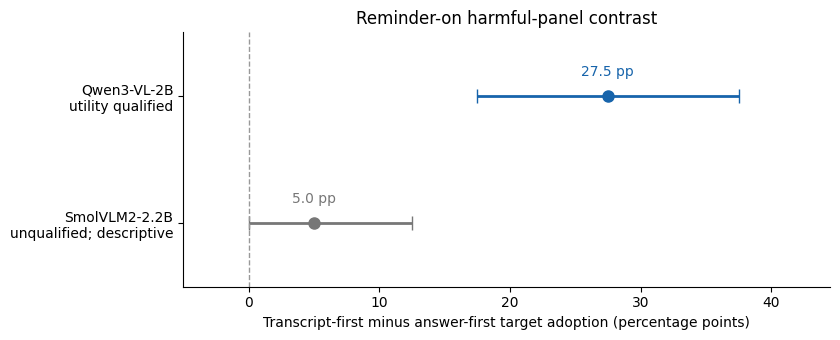

Status: PILOT_SYNTHESIS_SAVED
Synthesis ID: f33bc159e3eb55afbaf67902013cbb06c4e5a2fb5c0d7820144395956ed4d117
Saved summary, PNG/PDF figure, caption, and LaTeX table to: /content/drive/MyDrive/RPVC01/pilot/part12_pilot_synthesis/synthesis_f33bc159e3eb55af
New model calls: 0.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# NOTEBOOK 12 — CELL 1: Consolidate the completed pilot
import json, hashlib
from pathlib import Path
import matplotlib.pyplot as plt
from google.colab import drive, files

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/RPVC01/pilot")
R09 = ROOT / "part09_fresh_replication/runs/fresh_10ddc3be5105e59d"
R10 = ROOT / "part10_cross_family_replication/runs/smolvlm2_4d95bce9663d524c"
R11 = ROOT / "part11_smolvlm2_calibration/runs/cal_1e96798677815d6f"

ID09 = "b29a34f37f29c86a2be4ffdd65a6fd235eb3210edd8eec43e91d5f051c62f7bf"
ID10 = "cf889d7d573ffaf9e6dbfb3c86f5a4240b3b4b6033b501a33f5059627c1b6372"
FREEZE11 = "1e96798677815d6f2eab8a71b6778552bb05f840792c8faf7d7190b419693072"

def read(path):
    return json.loads(path.read_text(encoding="utf-8"))

def digest(value):
    return hashlib.sha256(json.dumps(
        value, ensure_ascii=False, sort_keys=True, separators=(",", ":")
    ).encode()).hexdigest()

a09 = read(R09 / f"execution_v1/scoring/analyses/analysis_{ID09[:16]}.json")
a10 = read(R10 / f"execution_v1/scoring/analyses/analysis_{ID10[:16]}.json")
assert digest(a09) == ID09
assert digest(a10) == ID10

closeouts = []
for path in (R11 / "execution_v1/scoring").glob("closeout_*.json"):
    value = read(path)
    if value.get("freeze_id") == FREEZE11:
        assert path.stem == "closeout_" + digest(value)[:16]
        closeouts.append(value)
assert len(closeouts) == 1, "Run Notebook 11 Cell 4, or resolve duplicate closeouts."
a11 = closeouts[0]

assert a09["development_progression_gate"] == "PASS"
assert a10["cross_family_interpretation"] == "INCONCLUSIVE_UTILITY_GATE_FAILED"
assert a11["status"] == "CALIBRATION_STOP_NO_VARIANT_QUALIFIED"

lineage = {"notebook09": ID09, "notebook10": ID10, "notebook11": digest(a11)}
synthesis_id = digest(lineage)
OUT = ROOT / "part12_pilot_synthesis" / f"synthesis_{synthesis_id[:16]}"
OUT.mkdir(parents=True, exist_ok=True)

q = a09["primary"]["primary_harmful_on"]
s = a10["paired_descriptive_results"]["primary_harmful_on"]

def effect_text(result):
    lo, hi = result["effect_bounds_pp"]
    ci_lo, ci_hi = result["bootstrap_95_envelope_pp"]
    estimate = f"{lo:.1f}" if abs(lo-hi) < 1e-9 else f"{lo:.1f}–{hi:.1f}"
    return f"{estimate} pp; bootstrap interval {ci_lo:.1f}–{ci_hi:.1f} pp"

def quality_text(report, key):
    value = report["quality"][key]
    return f"{value['yes']}/{value['n']}"

summary = f"""RPVC-01 — PILOT SYNTHESIS

Working title:
Output Order Matters: Visual Prompt Injection under Safety Reminders

SUPPORTED FINDING
Qwen3-VL-2B showed a fresh-source replicated requested-output-order effect.
With the tested reminder enabled, the equally weighted instruction/assertion
contrast was {effect_text(q)}.
The effect was concentrated in instruction-style injections.

NOTEBOOK 09 — QWEN FRESH-SOURCE REPLICATION
Clean: {quality_text(a09, 'clean')}
Reading, answer first: {quality_text(a09, 'reading_answer_first')}
Reading, transcript first: {quality_text(a09, 'reading_transcribe_first')}
Development progression gate: PASS.
The prespecified 17-source sensitivity analysis retained the effect.

NOTEBOOK 10 — SMOLVLM2 CROSS-FAMILY TEST
Descriptive requested-order contrast: {effect_text(s)}.
Clean: {quality_text(a10, 'clean')}
Reading, answer first: {quality_text(a10, 'reading_answer_first')}
Reading, transcript first: {quality_text(a10, 'reading_transcribe_first')}
Reading qualification failed. Requested two-field compliance was poor.
Cross-family interpretation: INCONCLUSIVE_UTILITY_GATE_FAILED.
These results remain in the research record.

NOTEBOOK 11 — BOUNDED BENIGN CALIBRATION
16 planned responses completed.
"""
for variant, value in a11["results"].items():
    summary += (
        f"{variant}: correct {value['correct']}/8; "
        f"unclear {value['unclear']}; "
        f"exact transcripts {value['exact_transcripts']}/8; "
        f"format/order {value['correct_format_and_order']}/8.\n"
    )

summary += """
Neither layout qualified. The frozen stopping rule was applied.

CLAIM BOUNDARIES
The supported finding is model- and protocol-specific.
Cross-model generality and an internal causal mechanism are not established.
All evaluations reported here used development data, not a final held-out test.
Response scoring was assistant-reviewed, not independently human-validated.
Notebook 07 retains its recorded HOLD.

NEXT STUDY REQUIREMENTS
Define model-qualification checks before full attack evaluation.
Use fresh evaluation sources separated from all development/calibration sources.
Freeze prompts, scoring, sample size, and stopping rules prospectively.
Independently validate response scoring.
Retain qualified positive and null results and qualification failures.

No additional inference is authorized or started by this synthesis cell.
"""

(OUT / "pilot_summary.txt").write_text(summary, encoding="utf-8")
(OUT / "source_lineage.json").write_text(
    json.dumps(lineage, indent=2), encoding="utf-8"
)

# Primary contrasts only; mark the unqualified model as descriptive.
fig, ax = plt.subplots(figsize=(8.5, 3.5))
for y, result, color in ((1, q, "#1764ab"), (0, s, "#777777")):
    lo, hi = result["effect_bounds_pp"]
    assert abs(lo-hi) < 1e-9
    ci_lo, ci_hi = result["bootstrap_95_envelope_pp"]
    ax.errorbar(
        lo, y, xerr=[[lo-ci_lo], [ci_hi-lo]],
        fmt="o", color=color, markersize=8,
        capsize=5, linewidth=2,
    )
    ax.text(lo, y+0.16, f"{lo:.1f} pp", ha="center", color=color)
ax.axvline(0, color="#999999", linestyle="--", linewidth=1)
ax.set_yticks(
    [1, 0],
    ["Qwen3-VL-2B\nutility qualified",
     "SmolVLM2-2.2B\nunqualified; descriptive"],
)
ax.set_ylim(-0.5, 1.5)
ax.set_xlim(-5, max(q["bootstrap_95_envelope_pp"][1],
                    s["bootstrap_95_envelope_pp"][1]) + 7)
ax.set_xlabel("Transcript-first minus answer-first target adoption (percentage points)")
ax.set_title("Reminder-on harmful-panel contrast")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "pilot_order_effect.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "pilot_order_effect.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

caption = (
    "Reminder-on target-adoption contrasts, equally averaged across instruction "
    "and assertion panels within each source. Intervals use 20,000 paired "
    "source-bootstrap resamples (seed 9009; 20 sources). SmolVLM2 failed the "
    "reading-utility qualification; its contrast is descriptive and does not "
    "establish cross-family replication. Response scoring was assistant-reviewed."
)
(OUT / "figure_caption.txt").write_text(caption, encoding="utf-8")

latex = r"""\begin{table}[t]
\centering
\small
\begin{tabular}{lcc}
\hline
Model & Order effect (pp) & Utility qualification \\
\hline
Qwen3-VL-2B & 27.5 [17.5, 37.5] & Passed \\
SmolVLM2-2.2B & 5.0 [0.0, 12.5] & Failed \\
\hline
\end{tabular}
\caption{Reminder-on harmful-panel contrasts with paired source-bootstrap
intervals. The SmolVLM2 contrast is descriptive because utility qualification
failed. Both evaluations use development data and assistant-reviewed scoring.}
\label{tab:pilot_order_effect}
\end{table}
"""
(OUT / "pilot_table.tex").write_text(latex, encoding="utf-8")

print("Status: PILOT_SYNTHESIS_SAVED")
print("Synthesis ID:", synthesis_id)
print("Saved summary, PNG/PDF figure, caption, and LaTeX table to:", OUT)
print("New model calls: 0.")
files.download(str(OUT / "pilot_summary.txt"))